# Singapore Urban Greenery Coverage (Regression)

In [49]:
import matplotlib.pyplot as plt 
import seaborn as sns 
import pandas as pd 
import numpy as np 
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, learning_curve
from sklearn.preprocessing import RobustScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import pearsonr, f_oneway 
import joblib 

## Data Loading 

In [2]:
sg_greenery_coverage_df = pd.read_csv("singapore_urban_greenery_synthetic_data.csv")
sg_greenery_coverage_df.head()

,planning_area,land_area_km2,building_density_pct,population_density_per_km2,distance_nearest_park_km,number_of_parks,nearby_park_area_km2,road_density_km_per_km2,greenery_coverage_pct
0,Bedok,10.30,29.2,5046,1.62,18,1.397,3.64,75.0
1,Serangoon,13.21,33.3,5239,0.54,14,1.350,15.98,64.1
2,Punggol,7.63,28.0,5441,2.23,25,0.511,21.06,75.0
3,Jurong East,4.85,43.7,18299,2.04,20,0.961,18.75,75.0
4,Jurong East,4.69,57.1,5610,0.91,1,0.139,8.27,5.0


In [3]:
sg_greenery_coverage_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   planning_area               500 non-null    object 
 1   land_area_km2               500 non-null    float64
 2   building_density_pct        500 non-null    float64
 3   population_density_per_km2  500 non-null    int64  
 4   distance_nearest_park_km    500 non-null    float64
 5   number_of_parks             500 non-null    int64  
 6   nearby_park_area_km2        500 non-null    float64
 7   road_density_km_per_km2     500 non-null    float64
 8   greenery_coverage_pct       500 non-null    float64
dtypes: float64(6), int64(2), object(1)
memory usage: 35.3+ KB


## Feature Selection via Statistical Analysis 

### Planning Area 

In [4]:
groups = [group["greenery_coverage_pct"].values for name, group in sg_greenery_coverage_df.groupby('planning_area')]

f_stat, p_value = f_oneway(*groups)

print("F-Statistics: {:.4f}".format(f_stat))
print("p-value: {:.4f}".format(p_value))

F-Statistics: 1.0472
p-value: 0.4039


In [5]:
def pearson_correlation(feature):
    r_stat, p_val = pearsonr(sg_greenery_coverage_df[feature], sg_greenery_coverage_df['greenery_coverage_pct'])
    print("Pearson r: {:.4f}".format(r_stat))
    print("p-value: {:.4f}".format(p_val))

### Land Area Km2

In [6]:
pearson_correlation('land_area_km2')

Pearson r: 0.0321
p-value: 0.4743


### Building Density Pct

In [7]:
pearson_correlation('building_density_pct')

Pearson r: -0.2472
p-value: 0.0000


### Population Density Per Km2

In [8]:
pearson_correlation('population_density_per_km2')

Pearson r: -0.1026
p-value: 0.0218


### Distance Nearest Park (Km)

In [9]:
pearson_correlation('distance_nearest_park_km')

Pearson r: -0.0780
p-value: 0.0814


### Number of Parks

In [10]:
pearson_correlation('number_of_parks')

Pearson r: 0.8698
p-value: 0.0000


### Nearby Park Area (km2)

In [11]:
pearson_correlation('nearby_park_area_km2')

Pearson r: 0.3891
p-value: 0.0000


### Road Density kilometers per km2

In [12]:
pearson_correlation('road_density_km_per_km2')

Pearson r: -0.3270
p-value: 0.0000


### Selected Features

In [13]:
sg_greenery_coverage_df = sg_greenery_coverage_df.drop(columns = ['planning_area', 'land_area_km2'], axis = 1)
sg_greenery_coverage_df.head()

,building_density_pct,population_density_per_km2,distance_nearest_park_km,number_of_parks,nearby_park_area_km2,road_density_km_per_km2,greenery_coverage_pct
0,29.2,5046,1.62,18,1.397,3.64,75.0
1,33.3,5239,0.54,14,1.350,15.98,64.1
2,28.0,5441,2.23,25,0.511,21.06,75.0
3,43.7,18299,2.04,20,0.961,18.75,75.0
4,57.1,5610,0.91,1,0.139,8.27,5.0


## Data Splitting

In [14]:
X_train, X_test, y_train, y_test = train_test_split(sg_greenery_coverage_df.drop(columns = ['greenery_coverage_pct'], axis = 1), 
                                                    sg_greenery_coverage_df['greenery_coverage_pct'], 
                                                    test_size = 0.2, 
                                                    shuffle = True, 
                                                    random_state = 42)

## Data Standardization 

In [15]:
feature_names = X_train.columns
feature_names

Index(['building_density_pct', 'population_density_per_km2',
       'distance_nearest_park_km', 'number_of_parks', 'nearby_park_area_km2',
       'road_density_km_per_km2'],
      dtype='object')

In [16]:
scaler = RobustScaler()
X_train[feature_names] = scaler.fit_transform(X_train[feature_names])
X_test[feature_names] = scaler.transform(X_test[feature_names])

In [17]:
X_train.head()

,building_density_pct,population_density_per_km2,distance_nearest_park_km,number_of_parks,nearby_park_area_km2,road_density_km_per_km2
249,-0.404608,0.329971,0.093306,-0.244898,-0.153907,-0.894074
433,-0.603312,-0.412843,-0.653144,0.653061,-0.433307,0.797588
19,0.240461,-0.004781,0.709939,-0.163265,-0.614838,-0.531201
322,-0.093593,0.111131,-0.385396,0.816327,0.723757,-0.852124
332,0.819294,-0.187239,0.417850,-0.244898,-0.838990,-0.038280


In [18]:
X_test.head()

,building_density_pct,population_density_per_km2,distance_nearest_park_km,number_of_parks,nearby_park_area_km2,road_density_km_per_km2
361,-0.133909,0.554487,0.125761,0.653061,-0.097080,0.086523
73,0.323974,0.576021,0.255578,0.816327,0.756906,0.687467
374,-0.131030,-0.199988,-0.182556,-0.653061,0.635359,-0.724174
155,0.303816,-0.416419,-0.052738,-0.653061,-0.092344,0.886733
104,-0.534197,0.749849,0.750507,-0.571429,0.103394,-0.897221


## Model Training 

In [19]:
cv = KFold(n_splits = 5, shuffle = True, random_state = 42)

#### Decision Trees

In [21]:
dt = DecisionTreeRegressor(random_state = 42)

dt_params = {"max_depth": [3, 5, 10, None], 
             "min_samples_split": [2, 5, 10]}

dt_grid = GridSearchCV(dt, 
                       dt_params, 
                       scoring = "neg_mean_squared_error", 
                       cv = cv, 
                       n_jobs = 1, 
                       return_train_score = True, 
                       verbose = 3)

dt_grid.fit(X_train, y_train)

print("Best Params: {}".format(dt_grid.best_params_))
print("Best Score: {}".format(dt_grid.best_score_))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV 1/5] END max_depth=3, min_samples_split=2;, score=(train=-99.001, test=-111.578) total time=   0.0s
[CV 2/5] END max_depth=3, min_samples_split=2;, score=(train=-93.003, test=-111.819) total time=   0.0s
[CV 3/5] END max_depth=3, min_samples_split=2;, score=(train=-87.704, test=-171.255) total time=   0.0s
[CV 4/5] END max_depth=3, min_samples_split=2;, score=(train=-83.499, test=-124.198) total time=   0.0s
[CV 5/5] END max_depth=3, min_samples_split=2;, score=(train=-83.780, test=-154.567) total time=   0.0s
[CV 1/5] END max_depth=3, min_samples_split=5;, score=(train=-99.001, test=-111.578) total time=   0.0s
[CV 2/5] END max_depth=3, min_samples_split=5;, score=(train=-93.003, test=-111.819) total time=   0.0s
[CV 3/5] END max_depth=3, min_samples_split=5;, score=(train=-87.704, test=-171.255) total time=   0.0s
[CV 4/5] END max_depth=3, min_samples_split=5;, score=(train=-83.499, test=-124.198) total time=   0.0s
[CV

#### Random Forest

In [22]:
rf = RandomForestRegressor(random_state = 42)

rf_params = {"n_estimators": [100, 200, 300], 
             "max_depth": [5, 10, None]}

rf_grid = GridSearchCV(rf, 
                       rf_params, 
                       scoring = "neg_mean_squared_error", 
                       cv = cv, 
                       n_jobs = 1, 
                       return_train_score = True, 
                       verbose = 3)

rf_grid.fit(X_train, y_train)

print("Best Params: {}".format(rf_grid.best_params_))
print("Best Score: {}".format(rf_grid.best_score_))

Fitting 5 folds for each of 9 candidates, totalling 45 fits
[CV 1/5] END max_depth=5, n_estimators=100;, score=(train=-18.584, test=-38.202) total time=   0.1s
[CV 2/5] END max_depth=5, n_estimators=100;, score=(train=-17.299, test=-54.704) total time=   0.1s
[CV 3/5] END max_depth=5, n_estimators=100;, score=(train=-17.348, test=-70.698) total time=   0.1s
[CV 4/5] END max_depth=5, n_estimators=100;, score=(train=-18.442, test=-49.388) total time=   0.1s
[CV 5/5] END max_depth=5, n_estimators=100;, score=(train=-17.226, test=-62.409) total time=   0.1s
[CV 1/5] END max_depth=5, n_estimators=200;, score=(train=-18.926, test=-38.171) total time=   0.3s
[CV 2/5] END max_depth=5, n_estimators=200;, score=(train=-16.439, test=-56.090) total time=   0.2s
[CV 3/5] END max_depth=5, n_estimators=200;, score=(train=-16.250, test=-69.786) total time=   0.2s
[CV 4/5] END max_depth=5, n_estimators=200;, score=(train=-18.780, test=-51.299) total time=   0.2s
[CV 5/5] END max_depth=5, n_estimators=2

#### Gradient Boosting

In [23]:
gb = GradientBoostingRegressor(random_state = 42)

gb_params = {"n_estimators": [100, 200, 300], 
             "learning_rate": [0.01, 0.05, 0.1]}

gb_grid = GridSearchCV(gb, 
                       gb_params, 
                       scoring = "neg_mean_squared_error", 
                       cv = cv, 
                       n_jobs = 1, 
                       return_train_score = True, 
                       verbose = 3)

gb_grid.fit(X_train, y_train)

print("Best Params: {}".format(gb_grid.best_params_))
print("Best Score: {}".format(gb_grid.best_score_))

Fitting 5 folds for each of 9 candidates, totalling 45 fits
[CV 1/5] END learning_rate=0.01, n_estimators=100;, score=(train=-161.851, test=-165.697) total time=   0.1s
[CV 2/5] END learning_rate=0.01, n_estimators=100;, score=(train=-155.618, test=-189.474) total time=   0.0s
[CV 3/5] END learning_rate=0.01, n_estimators=100;, score=(train=-156.382, test=-185.051) total time=   0.0s
[CV 4/5] END learning_rate=0.01, n_estimators=100;, score=(train=-160.017, test=-181.274) total time=   0.0s
[CV 5/5] END learning_rate=0.01, n_estimators=100;, score=(train=-153.789, test=-202.602) total time=   0.0s
[CV 1/5] END learning_rate=0.01, n_estimators=200;, score=(train=-54.223, test=-64.979) total time=   0.1s
[CV 2/5] END learning_rate=0.01, n_estimators=200;, score=(train=-51.221, test=-85.672) total time=   0.1s
[CV 3/5] END learning_rate=0.01, n_estimators=200;, score=(train=-50.324, test=-104.608) total time=   0.1s
[CV 4/5] END learning_rate=0.01, n_estimators=200;, score=(train=-53.984,

### Extra Trees

In [24]:
et = ExtraTreesRegressor(random_state = 42)

et_params = {"n_estimators": [100, 200, 300], 
             "max_depth": [5, 10, None]}

et_grid = GridSearchCV(et, 
                       et_params, 
                       scoring = "neg_mean_squared_error", 
                       cv = cv, 
                       n_jobs = 1, 
                       return_train_score = True, 
                       verbose = 3)

et_grid.fit(X_train, y_train)

print("Best Params: {}".format(et_grid.best_params_))
print("Best Score: {}".format(et_grid.best_score_))

Fitting 5 folds for each of 9 candidates, totalling 45 fits
[CV 1/5] END max_depth=5, n_estimators=100;, score=(train=-47.168, test=-50.802) total time=   0.0s
[CV 2/5] END max_depth=5, n_estimators=100;, score=(train=-41.767, test=-64.524) total time=   0.0s
[CV 3/5] END max_depth=5, n_estimators=100;, score=(train=-36.805, test=-80.612) total time=   0.0s
[CV 4/5] END max_depth=5, n_estimators=100;, score=(train=-41.954, test=-58.947) total time=   0.0s
[CV 5/5] END max_depth=5, n_estimators=100;, score=(train=-43.258, test=-64.238) total time=   0.0s
[CV 1/5] END max_depth=5, n_estimators=200;, score=(train=-47.169, test=-51.774) total time=   0.1s
[CV 2/5] END max_depth=5, n_estimators=200;, score=(train=-41.633, test=-62.542) total time=   0.1s
[CV 3/5] END max_depth=5, n_estimators=200;, score=(train=-37.759, test=-77.987) total time=   0.1s
[CV 4/5] END max_depth=5, n_estimators=200;, score=(train=-42.277, test=-59.431) total time=   0.1s
[CV 5/5] END max_depth=5, n_estimators=2

## Model Evaluation 

In [25]:
train_sizes = np.linspace(0.1, 1.0, 10)

### Decision Trees

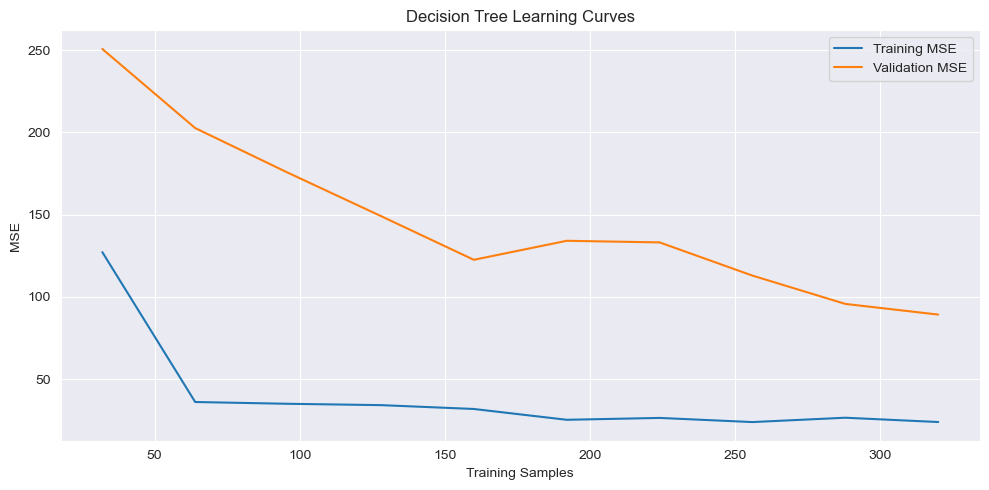

In [41]:
dt_sizes, dt_train, dt_valid = learning_curve(dt_grid.best_estimator_, 
                                              X_train, 
                                              y_train, 
                                              train_sizes = train_sizes, 
                                              cv = cv, 
                                              scoring = "neg_mean_squared_error", 
                                              n_jobs = 1)

sns.set_style("darkgrid")
plt.figure(figsize = (10, 5))
plt.plot(dt_sizes, -dt_train.mean(axis = 1), label = "Training MSE")
plt.plot(dt_sizes, -dt_valid.mean(axis = 1), label = "Validation MSE")
plt.title("Decision Tree Learning Curves")
plt.xlabel("Training Samples")
plt.ylabel("MSE")
plt.legend()
plt.tight_layout()
plt.show()

In [39]:
dt_train_pred = dt_grid.best_estimator_.predict(X_train)
dt_test_pred = dt_grid.best_estimator_.predict(X_test)

print("Train MAE: {:.4f}".format(mean_absolute_error(y_train, dt_train_pred)))
print("Train MSE: {:.4f}".format(mean_squared_error(y_train, dt_train_pred)))
print("Train RMSE: {:.4f}".format(np.sqrt(mean_squared_error(y_train, dt_train_pred))))
print("Train R2: {:.4f}".format(r2_score(y_train, dt_train_pred)))

print()
print("Test MAE: {:.4f}".format(mean_absolute_error(y_test, dt_test_pred)))
print("Test MSE: {:.4f}".format(mean_squared_error(y_test, dt_test_pred)))
print("Test RMSE: {:.4f}".format(np.sqrt(mean_squared_error(y_test, dt_test_pred))))
print("Test R2: {:.4f}".format(r2_score(y_test, dt_test_pred)))

Train MAE: 2.6673
Train MSE: 22.3651
Train RMSE: 4.7292
Train R2: 0.9706

Test MAE: 6.1845
Test MSE: 95.8615
Test RMSE: 9.7909
Test R2: 0.8610


### Random Forest

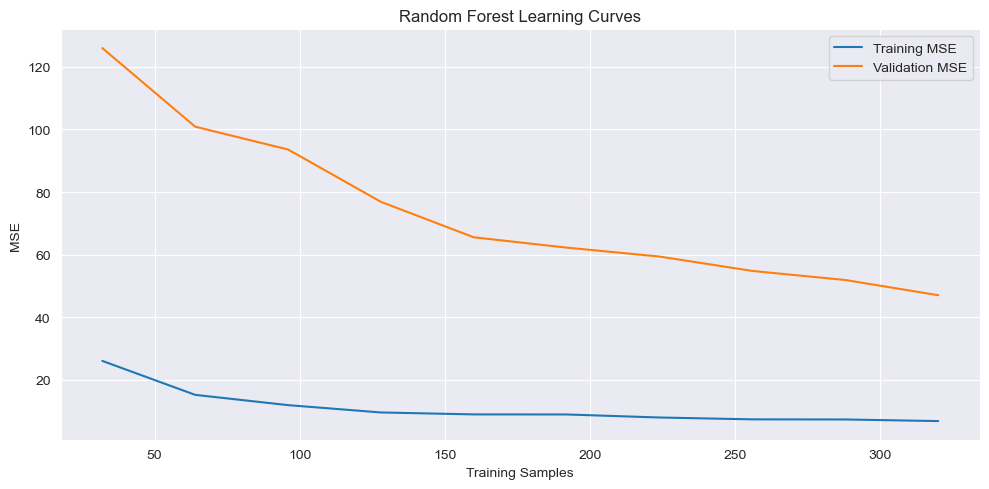

In [42]:
rf_sizes, rf_train, rf_valid = learning_curve(rf_grid.best_estimator_, 
                                              X_train, 
                                              y_train, 
                                              train_sizes = train_sizes, 
                                              cv = cv, 
                                              scoring = "neg_mean_squared_error", 
                                              n_jobs = 1)

sns.set_style("darkgrid")
plt.figure(figsize = (10, 5))
plt.plot(rf_sizes, -rf_train.mean(axis = 1), label = "Training MSE")
plt.plot(rf_sizes, -rf_valid.mean(axis = 1), label = "Validation MSE")
plt.title("Random Forest Learning Curves")
plt.xlabel("Training Samples")
plt.ylabel("MSE")
plt.legend()
plt.tight_layout()
plt.show()

In [43]:
rf_train_pred = rf_grid.best_estimator_.predict(X_train)
rf_test_pred = rf_grid.best_estimator_.predict(X_test)

print("Train MAE: {:.4f}".format(mean_absolute_error(y_train, rf_train_pred)))
print("Train MSE: {:.4f}".format(mean_squared_error(y_train, rf_train_pred)))
print("Train RMSE: {:.4f}".format(np.sqrt(mean_squared_error(y_train, rf_train_pred))))
print("Train R2: {:.4f}".format(r2_score(y_train, rf_train_pred)))

print()
print("Test MAE: {:.4f}".format(mean_absolute_error(y_test, rf_test_pred)))
print("Test MSE: {:.4f}".format(mean_squared_error(y_test, rf_test_pred)))
print("Test RMSE: {:.4f}".format(np.sqrt(mean_squared_error(y_test, rf_test_pred))))
print("Test R2: {:.4f}".format(r2_score(y_test, rf_test_pred)))

Train MAE: 1.6197
Train MSE: 6.3534
Train RMSE: 2.5206
Train R2: 0.9916

Test MAE: 4.2439
Test MSE: 41.0231
Test RMSE: 6.4049
Test R2: 0.9405


### Gradient Boosting

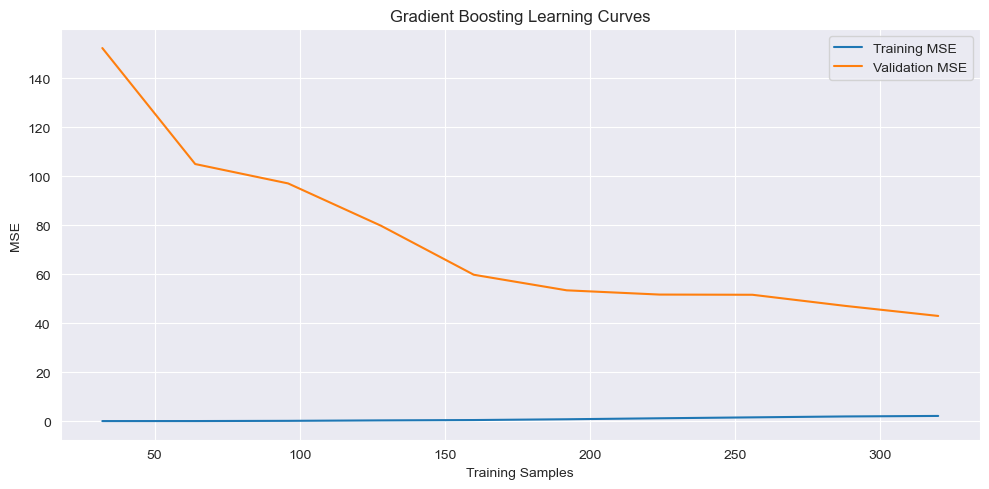

In [44]:
gb_sizes, gb_train, gb_valid = learning_curve(gb_grid.best_estimator_, 
                                              X_train, 
                                              y_train, 
                                              train_sizes = train_sizes, 
                                              cv = cv, 
                                              scoring = "neg_mean_squared_error", 
                                              n_jobs = 1)

sns.set_style("darkgrid")
plt.figure(figsize = (10, 5))
plt.plot(gb_sizes, -gb_train.mean(axis = 1), label = "Training MSE")
plt.plot(gb_sizes, -gb_valid.mean(axis = 1), label = "Validation MSE")
plt.title("Gradient Boosting Learning Curves")
plt.xlabel("Training Samples")
plt.ylabel("MSE")
plt.legend()
plt.tight_layout()
plt.show()

In [45]:
gb_train_pred = gb_grid.best_estimator_.predict(X_train)
gb_test_pred = gb_grid.best_estimator_.predict(X_test)

print("Train MAE: {:.4f}".format(mean_absolute_error(y_train, gb_train_pred)))
print("Train MSE: {:.4f}".format(mean_squared_error(y_train, gb_train_pred)))
print("Train RMSE: {:.4f}".format(np.sqrt(mean_squared_error(y_train, gb_train_pred))))
print("Train R2: {:.4f}".format(r2_score(y_train, gb_train_pred)))

print()
print("Test MAE: {:.4f}".format(mean_absolute_error(y_test, gb_test_pred)))
print("Test MSE: {:.4f}".format(mean_squared_error(y_test, gb_test_pred)))
print("Test RMSE: {:.4f}".format(np.sqrt(mean_squared_error(y_test, gb_test_pred))))
print("Test R2: {:.4f}".format(r2_score(y_test, gb_test_pred)))

Train MAE: 1.3220
Train MSE: 3.1339
Train RMSE: 1.7703
Train R2: 0.9959

Test MAE: 4.6635
Test MSE: 38.5199
Test RMSE: 6.2064
Test R2: 0.9441


### Extra Trees

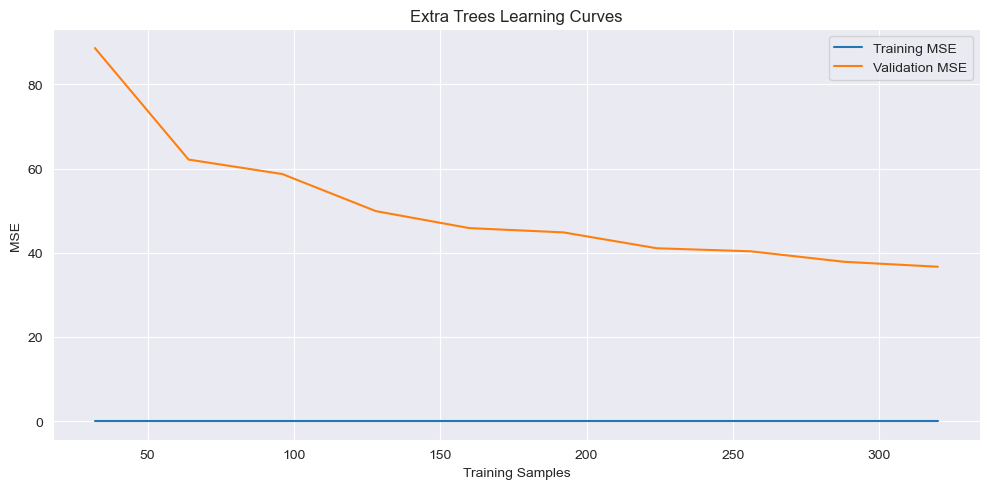

In [47]:
et_sizes, et_train, et_valid = learning_curve(et_grid.best_estimator_, 
                                              X_train, 
                                              y_train, 
                                              train_sizes = train_sizes, 
                                              cv = cv, 
                                              scoring = "neg_mean_squared_error", 
                                              n_jobs = 1)

sns.set_style("darkgrid")
plt.figure(figsize = (10, 5))
plt.plot(et_sizes, -et_train.mean(axis = 1), label = "Training MSE")
plt.plot(et_sizes, -et_valid.mean(axis = 1), label = "Validation MSE")
plt.title("Extra Trees Learning Curves")
plt.xlabel("Training Samples")
plt.ylabel("MSE")
plt.legend()
plt.tight_layout()
plt.show()

In [48]:
et_train_pred = et_grid.best_estimator_.predict(X_train)
et_test_pred = et_grid.best_estimator_.predict(X_test)

print("Train MAE: {:.4f}".format(mean_absolute_error(y_train, et_train_pred)))
print("Train MSE: {:.4f}".format(mean_squared_error(y_train, et_train_pred)))
print("Train RMSE: {:.4f}".format(np.sqrt(mean_squared_error(y_train, et_train_pred))))
print("Train R2: {:.4f}".format(r2_score(y_train, et_train_pred)))

print()
print("Test MAE: {:.4f}".format(mean_absolute_error(y_test, et_test_pred)))
print("Test MSE: {:.4f}".format(mean_squared_error(y_test, et_test_pred)))
print("Test RMSE: {:.4f}".format(np.sqrt(mean_squared_error(y_test, et_test_pred))))
print("Test R2: {:.4f}".format(r2_score(y_test, et_test_pred)))

Train MAE: 0.0000
Train MSE: 0.0000
Train RMSE: 0.0000
Train R2: 1.0000

Test MAE: 3.6885
Test MSE: 32.2023
Test RMSE: 5.6747
Test R2: 0.9533


## Saving Models

In [53]:
joblib.dump(dt_grid.best_estimator_, "decision_tree.pkl")
joblib.dump(rf_grid.best_estimator_, "random_forest.pkl")
joblib.dump(gb_grid.best_estimator_, "gradient_boosting.pkl")
joblib.dump(et_grid.best_estimator_, "extra_trees.pkl")
joblib.dump(scaler, "scaler.pkl")
print("All four models saved successfully!")

All four models saved successfully!
